In [80]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../Files/titanic_data_updated.csv')

Load the Titanic dataset and display:


*   Dataset shape
*   First 10 rows
*   5 random samples

In [81]:
print("Dataset Shape:", df.shape)
print(df.head(10))
print(df.sample(5))

Dataset Shape: (891, 12)
   PassengerId Survived  Pclass  \
0            1       no   third   
1            2      yes   first   
2            3      yes   third   
3            4      yes   first   
4            5       no   third   
5            6       no   third   
6            7       no   first   
7            8       no   third   
8            9      yes   third   
9           10      yes  second   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   
5                                   Moran, Mr. James    male   NaN      0   
6                            McCarthy, Mr. Timothy

Question 2 (10 Marks)
Perform feature screening on the Titanic dataset by:
*  Finding total missing values
*  Finding duplicate rows
*  Removing duplicate rows permanently


In [82]:
x = df.isnull().sum().sum()
print(f'Total Missing Values: {x}')
print(f"Duplicate Rows : {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)

Total Missing Values: 866
Duplicate Rows : 0


### Question 3 (10 Marks) 
Perform statistical profiling of the Titanic dataset and display:
*  Dataset information
*  Statistical summary of numerical columns

Also write 2 observations from the output.

In [83]:
df.info()
x = df.select_dtypes(include='number')
x.describe()
print(f'1. Missing data: \nAge = {891-714} \nCabin = {891 - 204}\nEmbarked = {891 - 889}')
print(f"2. Fare is highly skewed on the right side")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    object 
 2   Pclass       891 non-null    object 
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(3), object(7)
memory usage: 83.7+ KB
1. Missing data: 
Age = 177 
Cabin = 687
Embarked = 2
2. Fare is highly skewed on the right side


### Question 4 (10 Marks)
Perform univariate categorical analysis on the Survived column by:
*  Creating a countplot
*  Calculating percentage distribution
*  Creating a pie chart

Write 2 insights from the analysis.

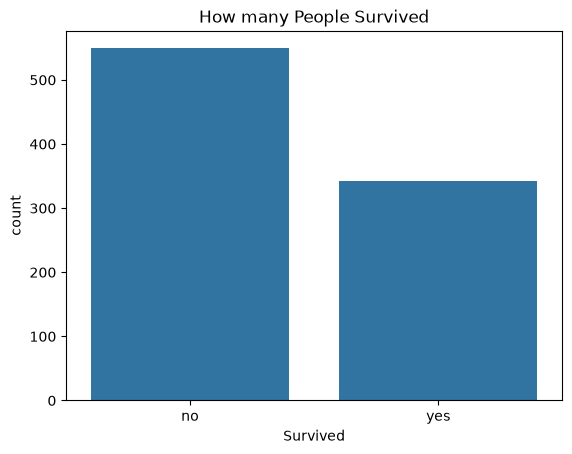

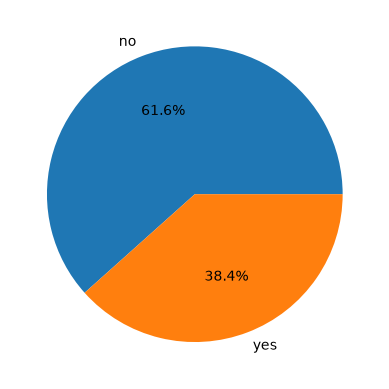

1. majority of people didt survived
2. few people are survived


In [84]:
plt.title('How many People Survived')
sns.countplot(data=df, x=df['Survived'])
plt.show()
dist_per = df['Survived'].value_counts(normalize=True)
dist_per
plt.pie(dist_per, labels=dist_per.index,autopct='%1.1f%%')
plt.show()

print('1. majority of people didt survived')
print('2. few people are survived')

### Question 5 (10 Marks)
Perform univariate numerical analysis on the Age column by:
*  Creating a histogram
*  Creating a KDE plot

Write 2 observations from the plots.


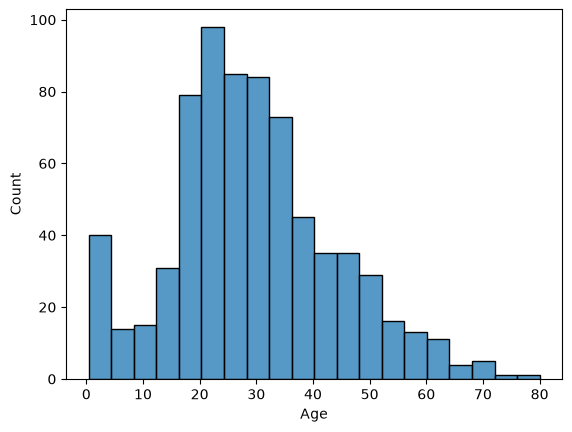

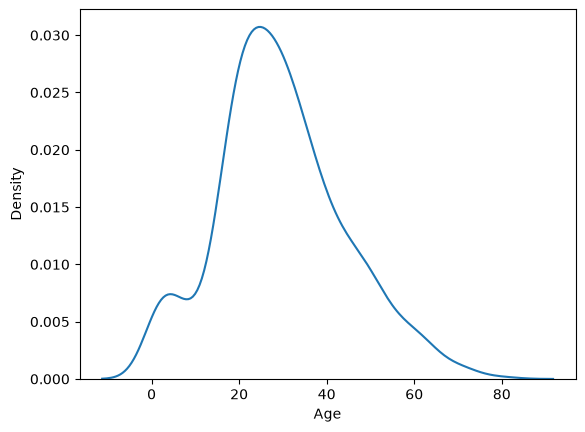

1. Most of the peoples age between 20-35 
2.age is skewed on the right side


In [85]:
sns.histplot(data=df, x=df['Age'])
plt.show()

sns.kdeplot(data=df, x='Age')
plt.show()

print('1. Most of the peoples age between 20-35 \n2.age is skewed on the right side')


### Question 6 (10 Marks)
Perform multivariate analysis between Sex and Survived using a countplot with hue.

Also calculate normalized survival ratios using groupby().

Write 2 insights from the analysis.

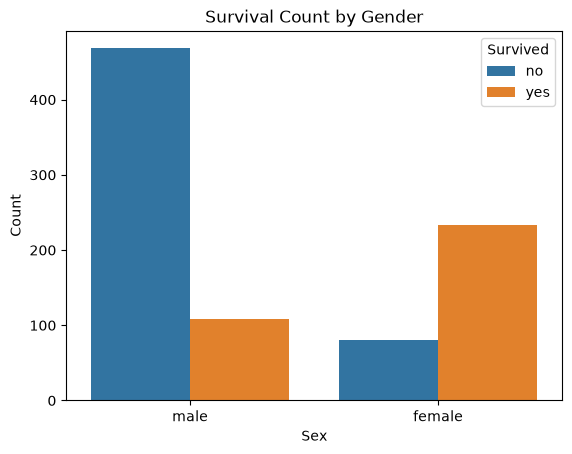

Sex     Survived
female  yes         0.742038
        no          0.257962
male    no          0.811092
        yes         0.188908
Name: proportion, dtype: float64
1. Survival rate of women is 74.2%
2. only few percent men survive


In [86]:
sns.countplot(data=df, x=df['Sex'], hue=df['Survived'])
plt.title('Survival Count by Gender')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.show()
survival_group = df.groupby('Sex')['Survived'].value_counts(normalize=True)
print(survival_group)
print('1. Survival rate of women is 74.2%\n2. only few percent men survive')

### Question 7 (10 Marks)
Create a barplot showing the relationship between Pclass and Fare.

Write 2 observations from the visualization.


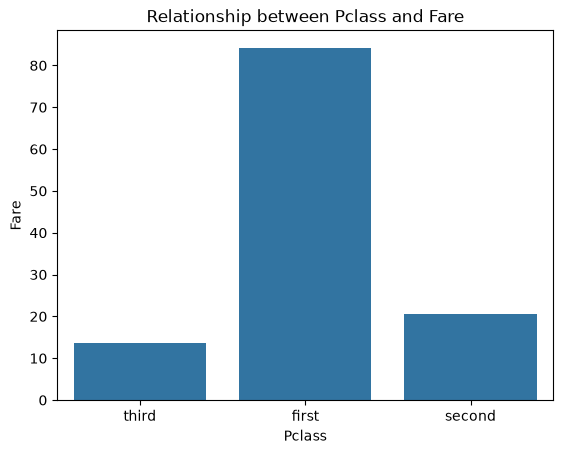

1. only the first pclass are paid more than the other pclass
2. second and third class pays less


In [87]:
sns.barplot(data=df, x=df['Pclass'], y=df['Fare'], errorbar=None)
plt.title('Relationship between Pclass and Fare')
plt.xlabel('Pclass')
plt.ylabel('Fare')
plt.show()
print('1. only the first pclass are paid more than the other pclass\n2. second and third class pays less')

### Question 8 (10 Marks)
Create a KDE plot to compare the Age distribution of survived and non-survived passengers.

Write 2 insights from the graph.


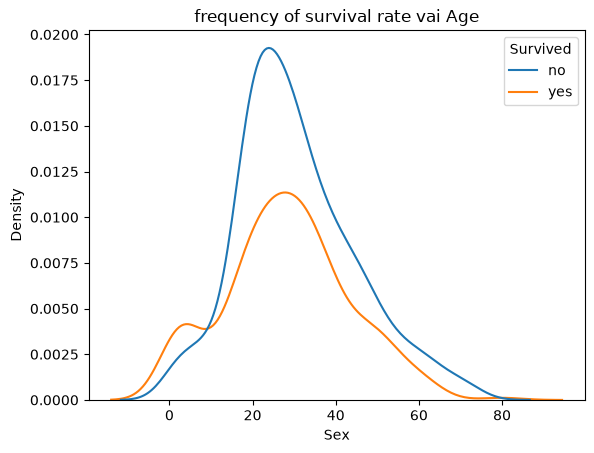

1. children (0-10) survival rete is high.
2. age between 20-40 has more density in both survival and none survival.


In [88]:
sns.kdeplot(data=df, x=df['Age'], hue='Survived')
plt.title('frequency of survival rate vai Age')
plt.xlabel('Sex')
plt.ylabel('Density')
plt.show()
print('1. children (0-10) survival rete is high.\n2. age between 20-40 has more density in both survival and none survival.')

### Question 9 (10 Marks)
Perform feature engineering and train-test split by:
*  Dropping PassengerId, Name, and Ticket columns
*  Separating features (X) and target (y)
*  Splitting the dataset using test_size=0.2 and random_state=42

Display the shapes of train and test datasets.


In [89]:
from sklearn.model_selection import train_test_split

df.drop(['PassengerId', "Name", "Ticket"], axis=1, inplace=True)
X = df.drop(['Survived'], axis=1)
y = df['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Shape of X_Train: ', X_train.shape)
print('Shape of y_Train: ', y_train.shape)
print("Shape of X_test: ", X_test.shape)
print("Shape of y_test: ", y_test.shape)

Shape of X_Train:  (712, 8)
Shape of y_Train:  (712,)
Shape of X_test:  (179, 8)
Shape of y_test:  (179,)


### Question 10 (10 Marks)
Handle missing values in the Titanic dataset by:
*  Imputing missing Age values using SimpleImputer with mean strategy
*  Imputing missing Embarked values using most frequent strategy
*  Imputing missing Cabin values using constant strategy with "Missing"

Finally, check whether any missing values remain.


In [98]:
from sklearn.impute import SimpleImputer
# Imputing missing Age values using SimpleImputer with mean strategy
age_imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
df['Age'] = age_imputer.fit_transform(df[['Age']]).ravel()
print('Missing value in Age:      ',df['Age'].isnull().sum())

#Imputing missing Embarked values using most frequent strategy
embark_imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
df['Embarked'] = embark_imputer.fit_transform(df[['Embarked']]).ravel()
print('Missing value in Embarked: ',df['Embarked'].isnull().sum())

#Imputing missing Cabin values using constant strategy with "Missing"
cabin_missing_imputer = SimpleImputer(missing_values=np.nan, strategy='constant', fill_value='Missing')
df['Cabin'] = cabin_missing_imputer.fit_transform(df[['Cabin']]).ravel()

print('Missing value in Cabin:    ',df['Cabin'].isnull().sum())

Missing value in Age:       0
Missing value in Embarked:  0
Missing value in Cabin:     0
